## 1. Model and dataset justification

The notebook compares **Multinomial Naive Bayes**, **Logistic Regression**, and **Linear SVM**. All three support sparse TF-IDF text features. Macro F1 is the main selection metric because it treats positive, neutral and negative classes equally despite the unequal class sizes.

The dataset is suitable because it includes labelled sentiment, free-text reviews, rating, date, provider, province, channel and known concern category. This supports both predictive modelling and customer-experience interpretation.

## 2. Analysis plan

1. Validate missing values, duplicates, ratings, dates and labels.
2. Analyse sentiment, ratings, concern categories, providers, channels, provinces, review length and monthly trends.
3. Clean text and convert it into TF-IDF unigrams and bigrams.
4. Use a stratified 80:20 train-test split.
5. Compare three classifiers using accuracy, precision, recall, macro F1 and weighted F1.
6. Tune Logistic Regression using five-fold GridSearchCV.
7. Interpret influential terms, inspect errors and prepare customer recommendations.

In [1]:
from pathlib import Path
import re, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, f1_score
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')


## 3. Load the dataset

In [2]:
candidate_files = [
    Path.cwd() / 'medical_aid_customer_reviews.csv',
    Path('/mnt/data/medical_aid_customer_reviews.csv')
]
DATA_FILE = next((p for p in candidate_files if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError('Place medical_aid_customer_reviews.csv in the same folder as this notebook.')
print('Loading:', DATA_FILE)
df = pd.read_csv(DATA_FILE)
display(df.head())


Loading: C:\Users\dzauakr\medical_aid_customer_reviews.csv


,review_id,review_date,provider,channel,province,rating,review_text,sentiment,known_concern_category
0,REV-0057,1/1/2024,MzanziCare Medical Aid,Web review,KwaZulu-Natal,1,Chronic medication approval requires repeated ...,negative,Chronic medicine
1,REV-0107,1/3/2024,WellLife Health Fund,Mobile app feedback,North West,1,Customer service transferred me repeatedly and...,negative,Customer service
2,REV-0424,1/3/2024,Ubuntu Health Medical Scheme,Web review,North West,2,Customer service transferred me repeatedly and...,negative,Customer service
3,REV-0385,1/6/2024,Ubuntu Health Medical Scheme,HelloPeter-style review,KwaZulu-Natal,3,The contribution changed after I added a depen...,neutral,Premiums and billing
4,REV-0471,1/10/2024,Ubuntu Health Medical Scheme,Mobile app feedback,KwaZulu-Natal,2,A chronic medicine was excluded even though it...,negative,Benefits and exclusions


## 4. Data quality and preparation

In [3]:
print('Shape:', df.shape)
display(pd.DataFrame({'Missing':df.isna().sum(),'Unique':df.nunique(dropna=False)}))
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate IDs:', df['review_id'].duplicated().sum())
print('Invalid ratings:', (~df['rating'].between(1,5)).sum())

df['review_date']=pd.to_datetime(df['review_date'], errors='coerce')
df['sentiment']=df['sentiment'].astype(str).str.strip().str.lower()
df['review_text']=df['review_text'].fillna('').astype(str).str.strip()
df['word_count']=df['review_text'].str.split().str.len()
df['year']=df['review_date'].dt.year
df['month']=df['review_date'].dt.to_period('M').dt.to_timestamp()
print('Date range:', df['review_date'].min().date(), 'to', df['review_date'].max().date())
print('Invalid sentiment labels:', (~df['sentiment'].isin({'positive','neutral','negative'})).sum())


Shape: (720, 9)


,Missing,Unique
review_id,0,720
review_date,0,515
provider,0,3
channel,0,3
province,0,9
rating,0,5
review_text,0,201
sentiment,0,3
known_concern_category,0,6


Duplicate rows: 0
Duplicate IDs: 0
Invalid ratings: 0
Date range: 2024-01-01 to 2026-10-30
Invalid sentiment labels: 0


## 5. Executive customer overview

In [4]:
summary=df['sentiment'].value_counts().rename_axis('Sentiment').reset_index(name='Reviews')
summary['Percentage']=(summary['Reviews']/len(df)*100).round(1)
kpis=pd.DataFrame({'KPI':['Total reviews','Average rating','Median rating','Average words','Providers','Channels','Provinces'],
                   'Value':[len(df),round(df.rating.mean(),2),df.rating.median(),round(df.word_count.mean(),1),df.provider.nunique(),df.channel.nunique(),df.province.nunique()]})
display(kpis); display(summary)


,KPI,Value
0,Total reviews,720.00
1,Average rating,2.38
2,Median rating,2.00
3,Average words,15.80
4,Providers,3.00
5,Channels,3.00
6,Provinces,9.00


,Sentiment,Reviews,Percentage
0,negative,436,60.6
1,positive,165,22.9
2,neutral,119,16.5


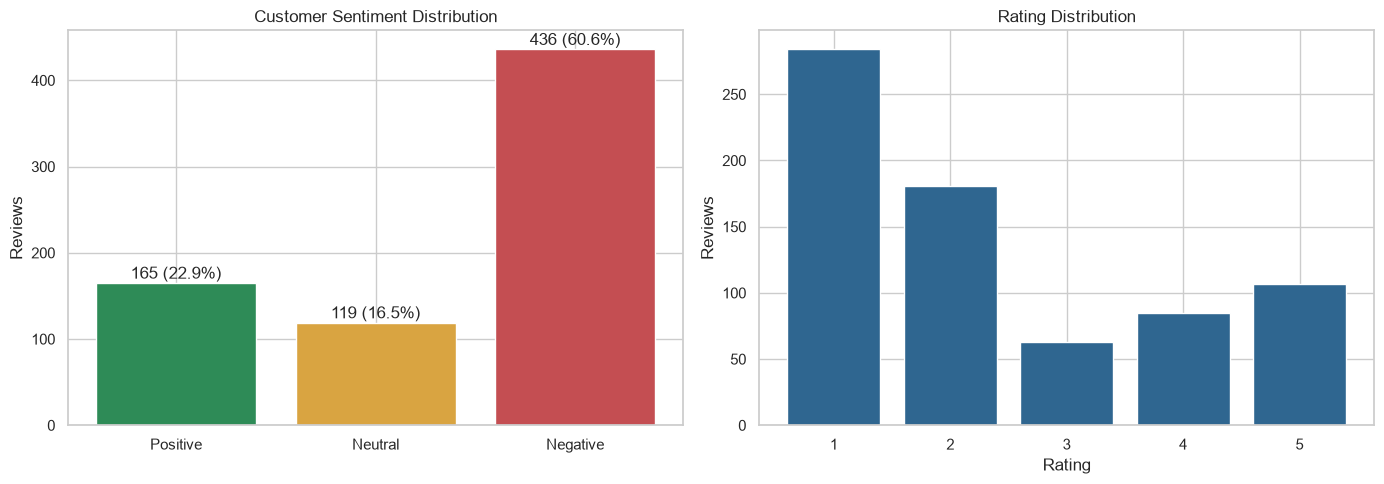

In [5]:
order=['positive','neutral','negative']; colors=['#2E8B57','#D9A441','#C44E52']
fig,axes=plt.subplots(1,2,figsize=(14,5))
counts=df.sentiment.value_counts().reindex(order)
axes[0].bar([s.title() for s in order],counts.values,color=colors)
axes[0].set_title('Customer Sentiment Distribution'); axes[0].set_ylabel('Reviews')
for i,v in enumerate(counts.values): axes[0].text(i,v+5,f'{v} ({v/len(df):.1%})',ha='center')
r=df.rating.value_counts().sort_index(); axes[1].bar(r.index.astype(str),r.values,color='#2F6690')
axes[1].set_title('Rating Distribution'); axes[1].set_xlabel('Rating'); axes[1].set_ylabel('Reviews')
plt.tight_layout(); plt.show()


## 6. Concern-category analysis

sentiment,negative,neutral,positive,Total,Negative %
known_concern_category,,,,,
Premiums and billing,76,21,35,132,57.6
Chronic medicine,84,17,26,127,66.1
Customer service,74,28,22,124,59.7
Benefits and exclusions,68,21,31,120,56.7
Claims processing,78,14,22,114,68.4
Pre-authorisation,56,18,29,103,54.4


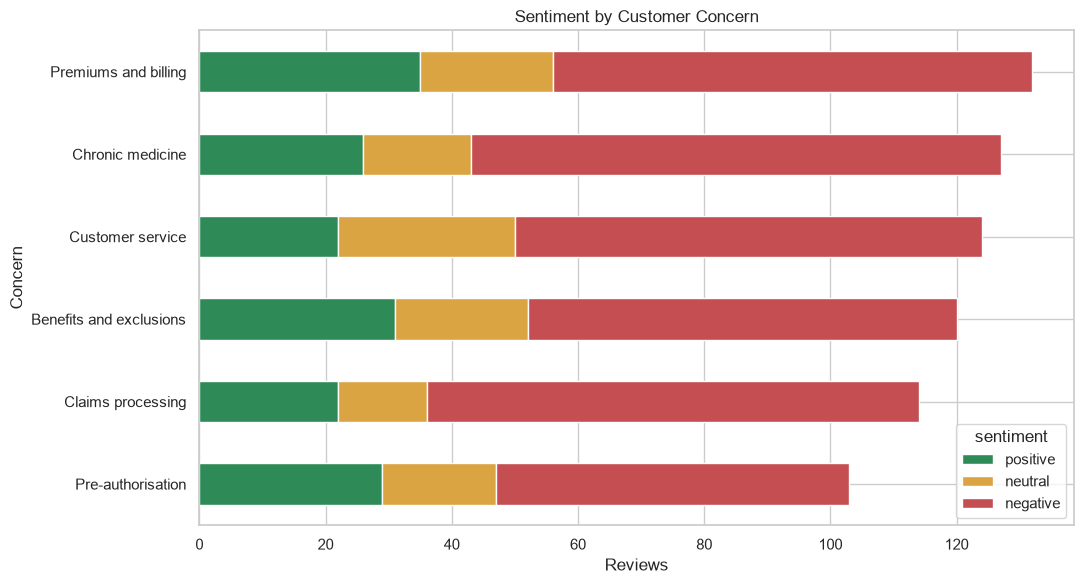

In [6]:
concerns=pd.crosstab(df.known_concern_category,df.sentiment)
concerns['Total']=concerns.sum(axis=1); concerns['Negative %']=(concerns.get('negative',0)/concerns.Total*100).round(1)
concerns=concerns.sort_values('Total',ascending=False); display(concerns)
plot_data=pd.crosstab(df.known_concern_category,df.sentiment).reindex(columns=order,fill_value=0)
plot_data=plot_data.loc[plot_data.sum(axis=1).sort_values().index]
plot_data.plot(kind='barh',stacked=True,figsize=(11,6),color=colors)
plt.title('Sentiment by Customer Concern'); plt.xlabel('Reviews'); plt.ylabel('Concern'); plt.tight_layout(); plt.show()


## 7. Provider, channel and province profiles

In [7]:
def profile(col):
    t=pd.crosstab(df[col],df.sentiment); t['Total']=t.sum(axis=1)
    t['Negative %']=(t.get('negative',0)/t.Total*100).round(1)
    t['Average rating']=df.groupby(col).rating.mean().round(2)
    return t.sort_values('Negative %',ascending=False)
print('Providers'); display(profile('provider'))
print('Channels'); display(profile('channel'))
print('Provinces'); display(profile('province'))


Providers


sentiment,negative,neutral,positive,Total,Negative %,Average rating
provider,,,,,,
WellLife Health Fund,162,36,52,250,64.8,2.32
Ubuntu Health Medical Scheme,151,43,54,248,60.9,2.35
MzanziCare Medical Aid,123,40,59,222,55.4,2.46


Channels


sentiment,negative,neutral,positive,Total,Negative %,Average rating
channel,,,,,,
HelloPeter-style review,156,30,57,243,64.2,2.31
Web review,145,43,46,234,62.0,2.31
Mobile app feedback,135,46,62,243,55.6,2.50


Provinces


sentiment,negative,neutral,positive,Total,Negative %,Average rating
province,,,,,,
North West,61,11,15,87,70.1,2.11
Mpumalanga,58,13,20,91,63.7,2.30
Free State,48,15,14,77,62.3,2.23
Gauteng,45,11,17,73,61.6,2.45
Western Cape,46,10,20,76,60.5,2.41
Limpopo,42,14,18,74,56.8,2.45
Northern Cape,44,14,20,78,56.4,2.44
KwaZulu-Natal,49,19,19,87,56.3,2.44
Eastern Cape,43,12,22,77,55.8,2.60


## 8. Review length and monthly volume

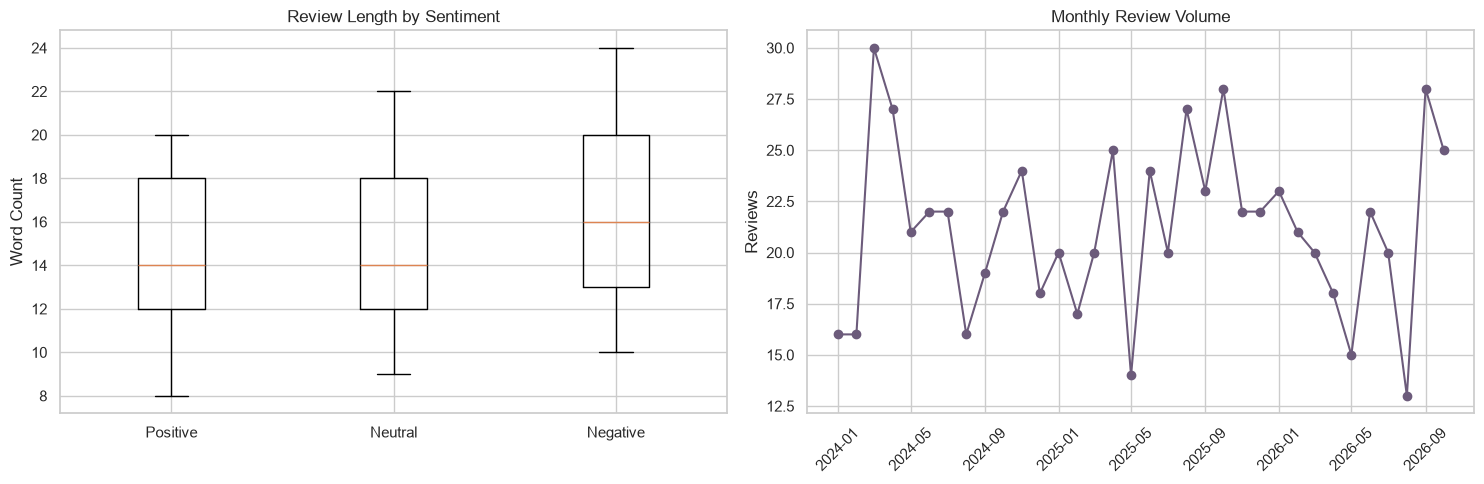

,count,mean,median,min,max
sentiment,,,,,
negative,436,16.57,16.0,10,24
neutral,119,14.88,14.0,9,22
positive,165,14.58,14.0,8,20


In [8]:
fig,axes=plt.subplots(1,2,figsize=(15,5))
box_data=[df.loc[df.sentiment.eq(s),'word_count'].dropna() for s in order]
axes[0].boxplot(box_data,tick_labels=[s.title() for s in order],showfliers=False)
axes[0].set_title('Review Length by Sentiment'); axes[0].set_ylabel('Word Count')
monthly=df.set_index('review_date').resample('MS').size()
axes[1].plot(monthly.index,monthly.values,marker='o',color='#6C5B7B')
axes[1].set_title('Monthly Review Volume'); axes[1].set_ylabel('Reviews'); axes[1].tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()
display(df.groupby('sentiment').word_count.agg(['count','mean','median','min','max']).round(2))


## 9. Monthly sentiment trend

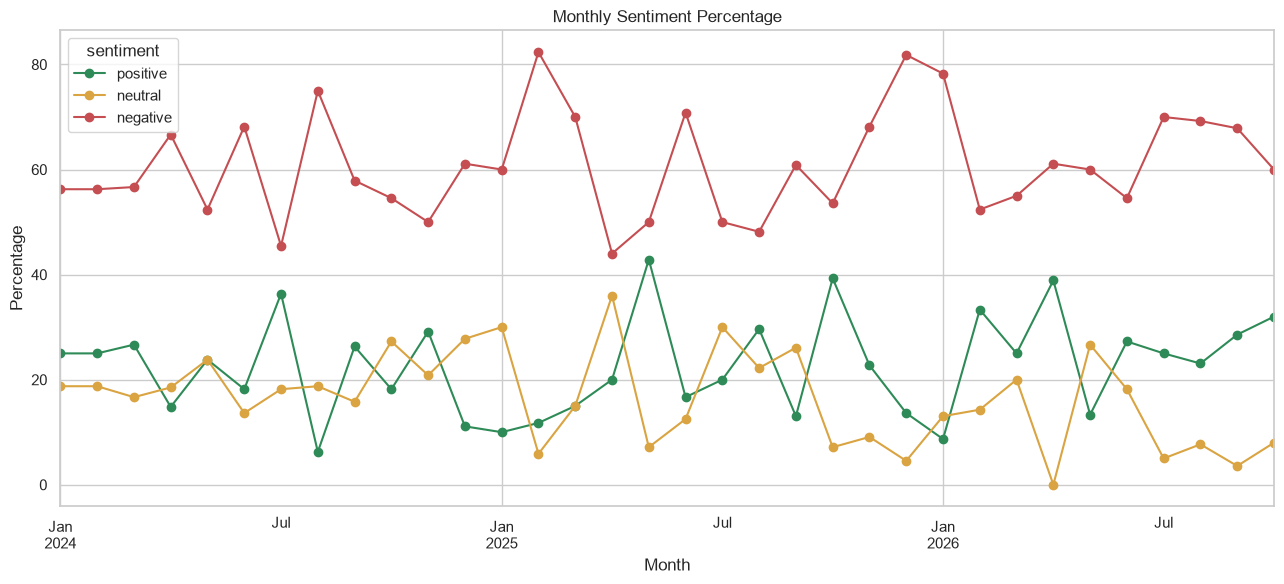

In [9]:
monthly_sentiment=pd.crosstab(df.month,df.sentiment).reindex(columns=order,fill_value=0)
monthly_pct=monthly_sentiment.div(monthly_sentiment.sum(axis=1),axis=0)*100
monthly_pct.plot(figsize=(13,6),marker='o',color=colors)
plt.title('Monthly Sentiment Percentage'); plt.xlabel('Month'); plt.ylabel('Percentage'); plt.tight_layout(); plt.show()


## 10. Text preparation and frequent terms

In [10]:
CUSTOM_STOPWORDS={'medical','aid','scheme','fund','review','service','please','would','could','also','still','received','customer'}
def clean_text(text):
    text=str(text).lower(); text=re.sub(r'https?://\S+|www\.\S+',' ',text)
    text=re.sub(r'[^a-z\s]',' ',text); return re.sub(r'\s+',' ',text).strip()
df['clean_text']=df.review_text.apply(clean_text)
def top_terms(frame,n=20):
    tokens=[]
    for text in frame.clean_text:
        tokens.extend([w for w in text.split() if len(w)>2 and w not in CUSTOM_STOPWORDS])
    return pd.DataFrame(Counter(tokens).most_common(n),columns=['Term','Frequency'])
print('All reviews'); display(top_terms(df))
print('Negative reviews'); display(top_terms(df[df.sentiment.eq('negative')]))
print('Positive reviews'); display(top_terms(df[df.sentiment.eq('positive')]))


All reviews


,Term,Frequency
0,the,1181
1,and,466
2,was,332
3,for,170
4,clear,148
5,not,136
6,claim,112
7,this,110
8,time,109
9,has,107


Negative reviews


,Term,Frequency
0,the,693
1,and,293
2,was,209
3,not,136
4,clear,115
5,has,107
6,time,99
7,appreciate,90
8,written,90
9,response,90


Positive reviews


,Term,Frequency
0,the,289
1,and,116
2,was,97
3,recommend,43
4,this,43
5,thank,39
6,you,39
7,for,39
8,efficient,39
9,assistance,39


## 11. Feature selection

TF-IDF converts customer text into weighted numerical features. Unigrams capture words and bigrams capture phrases such as “claim pending” and “clear explanation”. Terms appearing in fewer than three reviews are removed to reduce noise.

In [11]:
X=df.clean_text; y=df.sentiment
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print('Training:',len(X_train),'Testing:',len(X_test)); print(y_train.value_counts())


Training: 576 Testing: 144
sentiment
negative    349
positive    132
neutral      95
Name: count, dtype: int64


## 12. Train and compare models

In [12]:
models={'Multinomial Naive Bayes':MultinomialNB(),
        'Logistic Regression':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42),
        'Linear SVM':LinearSVC(class_weight='balanced',random_state=42)}
results=[]; fitted={}
for name,clf in models.items():
    pipe=Pipeline([('tfidf',TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=3,max_df=.95,max_features=5000,sublinear_tf=True)),('model',clf)])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    p,r,f,_=precision_recall_fscore_support(y_test,pred,average='macro',zero_division=0)
    results.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Macro precision':p,'Macro recall':r,'Macro F1':f,'Weighted F1':f1_score(y_test,pred,average='weighted')})
    fitted[name]=pipe
model_results=pd.DataFrame(results).sort_values('Macro F1',ascending=False)
display(model_results.style.format({c:'{:.3f}' for c in model_results.columns if c!='Model'}))


,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1
0,Multinomial Naive Bayes,0.986,0.993,0.972,0.982,0.986
1,Logistic Regression,0.986,0.993,0.972,0.982,0.986
2,Linear SVM,0.986,0.993,0.972,0.982,0.986


## 13. Evaluate the best baseline model

Best baseline: Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative      0.978     1.000     0.989        87
     neutral      1.000     0.917     0.957        24
    positive      1.000     1.000     1.000        33

    accuracy                          0.986       144
   macro avg      0.993     0.972     0.982       144
weighted avg      0.986     0.986     0.986       144



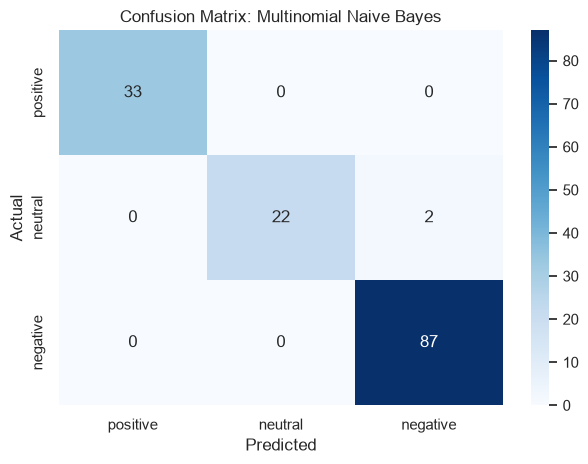

In [13]:
best_name=model_results.iloc[0].Model; best=fitted[best_name]; pred=best.predict(X_test)
print('Best baseline:',best_name); print(classification_report(y_test,pred,digits=3,zero_division=0))
labels=['positive','neutral','negative']; cm=confusion_matrix(y_test,pred,labels=labels)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels)
plt.title('Confusion Matrix: '+best_name); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()


## 14. Tune Logistic Regression

In [14]:
tuned=Pipeline([('tfidf',TfidfVectorizer(stop_words='english',sublinear_tf=True)),('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42))])
params={'tfidf__ngram_range':[(1,1),(1,2)],'tfidf__min_df':[2,3,5],'tfidf__max_features':[3000,5000],'model__C':[.5,1,2,5]}
grid=GridSearchCV(tuned,params,scoring='f1_macro',cv=5,n_jobs=-1); grid.fit(X_train,y_train)
tuned_pred=grid.predict(X_test)
print('Best parameters:',grid.best_params_); print('CV macro F1:',round(grid.best_score_,3))
print('Test accuracy:',round(accuracy_score(y_test,tuned_pred),3)); print('Test macro F1:',round(f1_score(y_test,tuned_pred,average='macro'),3))
print(classification_report(y_test,tuned_pred,digits=3,zero_division=0))


Best parameters: {'model__C': 0.5, 'tfidf__max_features': 3000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
CV macro F1: 1.0
Test accuracy: 0.986
Test macro F1: 0.982
              precision    recall  f1-score   support

    negative      0.978     1.000     0.989        87
     neutral      1.000     0.917     0.957        24
    positive      1.000     1.000     1.000        33

    accuracy                          0.986       144
   macro avg      0.993     0.972     0.982       144
weighted avg      0.986     0.986     0.986       144



## 15. Interpret influential terms and errors

In [15]:
final_model=grid.best_estimator_; vec=final_model.named_steps['tfidf']; clf=final_model.named_steps['model']; names=np.array(vec.get_feature_names_out())
for i,cls in enumerate(clf.classes_):
    idx=np.argsort(clf.coef_[i])[-15:][::-1]; print(); print(cls.upper()+':',', '.join(names[idx]))
errors=pd.DataFrame({'Review':X_test,'Actual':y_test,'Predicted':tuned_pred})
errors=errors[errors.Actual!=errors.Predicted]; print(); print('Errors:',len(errors),'of',len(X_test)); display(errors.head(15))



NEGATIVE: improve, improve turnaround, turnaround, turnaround time, appreciate clear, appreciate, written response, response, time, confidence, affected confidence, affected, confidence service, different, clear written

NEUTRAL: requested, outcome, final outcome, waiting, waiting final, subject, date, final, scheme explained, received, explained, rules, formulary subject, approved dosage, covered formulary

POSITIVE: quickly, recommend, recommend service, thank efficient, assistance, thank, efficient, efficient assistance, reflected, clearly, provided, team, handled, easy, helped

Errors: 2 of 144


,Review,Actual,Predicted
624,i submitted a new prescription after the previ...,neutral,negative
276,i submitted a new prescription after the previ...,neutral,negative


## 16. Customer report and recommendations

### Customer experience position
Negative feedback dominates the dataset at **60.6%**, compared with **22.9% positive** and **16.5% neutral** feedback. The mean rating of **2.38/5** confirms a material customer-experience problem.

### Main concern areas
- Premiums and billing: **132 reviews**
- Chronic medicine: **127 reviews**
- Customer service: **124 reviews**
- Benefits and exclusions: **120 reviews**
- Claims processing: **114 reviews**
- Pre-authorisation: **103 reviews**

### Recommended actions
1. **Claims:** validate documents at submission and show expected resolution dates.
2. **Pre-authorisation:** standardise requirements and issue one written checklist.
3. **Chronic medicine:** provide proactive renewal and formulary-change notifications.
4. **Billing:** provide itemised explanations for increases, deductions and refunds.
5. **Customer service:** assign one case owner and reduce repeated transfers.
6. **Benefits:** disclose exclusions and co-payments clearly before treatment where possible.

### Governance
The model can assist with triage and prioritisation. It must not replace complaint investigation, clinical review or medical-safety escalation. Review text may contain sensitive health information and must remain access controlled and de-identified.

## 17. Conclusion

This notebook provides the full PDANA pipeline: dataset justification, planning, data cleaning, exploratory analysis, feature selection, model training, interpretation, evaluation, tuning and customer reporting. The model should be monitored and periodically retrained as complaint language and service processes change.